# Tech Challenge Fase 2 — Classificando a qualidade de vinhos
## Notebook 01 · Compreensão do problema e Análise Exploratória (EDA)

**Objetivo deste notebook:** entender o problema de negócio, definir a variável alvo e investigar a base
(distribuições, outliers, correlações justificadas, testes estatísticos e balanceamento das classes) antes de
qualquer modelagem. As conclusões daqui orientam o pré-processamento e os modelos do notebook 02.

**Roteiro**
1. Compreensão do problema (contexto, variável alvo, métrica e hipóteses)
2. Visão geral da base e dicionário de dados
3. Qualidade dos dados (tipos, nulos, identificador, duplicatas)
4. Variável alvo e balanceamento
5. Estatística descritiva e distribuições
6. Outliers e valores inconsistentes
7. Comparação entre vinhos de alta e baixa/média qualidade
8. Correlações (com justificativa de cada uma)
9. Testes de hipótese
10. Conclusões da EDA e decisões para o pré-processamento

In [1]:
# Configuração do ambiente — funciona no Google Colab e localmente (Jupyter/VS Code)
import sys
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/igorsycko/postech15dtat-tech-challenge-2-wine.git"

if EM_COLAB:
    REPO_DIR = "/content/postech15dtat-tech-challenge-2-wine"
    if not Path(REPO_DIR).exists():
        !git clone -q {REPO_URL} {REPO_DIR}
    %cd {REPO_DIR}
    !pip install -q -r requirements.txt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
print("Raiz do projeto:", ROOT)

Raiz do projeto: /content/postech15dtat-tech-challenge-2-wine


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro, mannwhitneyu

from src.config import FEATURES, TARGET, LABELS_PT, UNITS, RESULTS_DIR, label
from src.data import load_raw, standardize_columns, create_target, duplicate_report, remove_duplicates
from src.preprocessing import iqr_outlier_table
from src import visualization as viz

viz.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Compreensão do problema

### 1.1 Contexto
A qualidade de um vinho é tradicionalmente julgada por especialistas em provas sensoriais — um processo
**subjetivo**, **demorado** e **dependente da experiência** de quem avalia, que acontece quando o vinho já está
pronto. Durante a produção, porém, a vinícola já mede várias características físico-químicas (acidez, teor
alcoólico, sulfatos, dióxido de enxofre etc.).

**Quem usa o resultado e para quê.** Enólogos e produtores. Um modelo preditivo pode:
- **apoiar a tomada de decisão**, sinalizando cedo lotes com tendência a alta ou baixa qualidade;
- **orientar ajustes no processo produtivo**, mostrando quais características mais pesam na qualidade;
- **contribuir para a padronização da qualidade** entre lotes e safras.

O modelo **apoia** a prova sensorial; ele não substitui o especialista, de quem herda o critério de avaliação.

### 1.2 Pergunta de negócio
*Com as medições de laboratório, conseguimos antecipar se um vinho tende a ser de alta qualidade — e saber quais
características mais pesam nessa avaliação para ajustar o processo?*

**Tipo de problema.** Aprendizado **supervisionado de classificação binária**: cada amostra tem a nota dada pelos
especialistas (rótulo), e queremos prever a classe de amostras novas a partir das 11 medições.

**Escopo e limites conhecidos desde o início**
- A base contém **apenas vinho tinto** de uma região (Vinho Verde, Portugal); conclusões não se estendem
  automaticamente a brancos ou a outras regiões.
- A nota é **subjetiva**: é a avaliação de provadores, não uma medida física.
- Os dados são **observacionais**: mostram associação entre química e qualidade, não causa.

### 1.3 Variável alvo
A variável de origem é `quality`, a nota dos especialistas. A escala teórica vai de **0 a 10**, mas na base as
notas observadas vão apenas de **3 a 8** (verificado abaixo). Seguindo o enunciado, ela é transformada em uma
classe binária chamada **`alta_qualidade`**:

| Classe | Regra | Valor de `alta_qualidade` |
|---|---|---|
| Alta qualidade | nota ≥ 7 | 1 |
| Baixa/média qualidade | nota < 7 | 0 |

**Por que o corte em 7?** O enunciado sugere esse corte ("por exemplo"), e ele faz sentido para o negócio: com
nota ≥ 7, a classe "alta" reúne cerca de 14% dos vinhos, o grupo que de fato se destaca (nível *premium*). Um corte
em 6 colocaria mais da metade da base como "alta" e deixaria de separar o excelente do mediano; um corte em 8
deixaria pouco mais de 1% dos vinhos na classe, insuficiente para um modelo aprender. A tabela abaixo mostra essa
comparação.

**A nota original não entra no modelo.** Depois de criar o alvo, `quality` deixa de ser variável explicativa:
como o alvo é derivado dela, usá-la como entrada seria **vazamento de dados** (o modelo "veria a resposta").
As variáveis explicativas são apenas as 11 medições físico-químicas.

In [3]:
# Transformação da nota em classe binária (feita aqui, na base completa recebida do Kaggle)
raw = load_raw()
df_full = standardize_columns(raw)                     # nomes em minúsculas e com "_"
df_full["alta_qualidade"] = (df_full["quality"] >= 7).astype(int)   # mesma regra de src.data.create_target

print("Notas observadas na base:", sorted(df_full["quality"].unique().tolist()))
print("Nome da variável alvo:", TARGET)

# Conferência: cada nota foi para a classe certa?
conferencia = pd.crosstab(df_full["quality"], df_full[TARGET], margins=True, margins_name="Total")
conferencia.columns = ["Baixa/média (0)", "Alta (1)", "Total"]
conferencia.index.name = "Nota (quality)"
conferencia

Notas observadas na base: [3, 4, 5, 6, 7, 8]
Nome da variável alvo: alta_qualidade


,Baixa/média (0),Alta (1),Total
Nota (quality),,,
3,6,0,6
4,33,0,33
5,483,0,483
6,462,0,462
7,0,143,143
8,0,16,16
Total,984,159,1143


In [4]:
# Comparação de cortes possíveis: qual fração da base ficaria na classe "alta"?
cortes = pd.DataFrame({
    "corte (nota ≥)": [6, 7, 8],
    "vinhos na classe 'alta'": [int((df_full["quality"] >= c).sum()) for c in (6, 7, 8)],
})
cortes["% da base"] = (100 * cortes["vinhos na classe 'alta'"] / len(df_full)).round(1)
cortes["leitura"] = ["mais da metade: não separa o excelente do mediano",
                     "≈ 1 em 7: grupo que se destaca (corte adotado)",
                     "≈ 1%: poucos exemplos para aprender"]
cortes

,corte (nota ≥),vinhos na classe 'alta',% da base,leitura
0,6,621,54.300,mais da metade: não separa o excelente do mediano
1,7,159,13.900,≈ 1 em 7: grupo que se destaca (corte adotado)
2,8,16,1.400,≈ 1%: poucos exemplos para aprender


**Conferência.** As notas 3, 4, 5 e 6 foram todas para a classe 0 e as notas 7 e 8 para a classe 1 — a
transformação está correta. A base recebida tem 159 vinhos de alta qualidade (13,9%); esse número muda levemente
depois da limpeza de duplicatas (seção 3).

### 1.4 Que erro custa mais?
Pergunta que as aulas pedem para responder antes de escolher a métrica:
- *Falso positivo* — prever "alta" para um vinho comum: risco de vender como *premium* algo que não é (marca).
- *Falso negativo* — prever "baixa/média" para um vinho bom: perda de receita (vinho *premium* vendido como comum).

Os dois erros têm custo, por isso a métrica principal será o **F1 da classe "alta"** (equilíbrio entre precisão e
recall), acompanhada de recall, precisão, ROC-AUC e PR-AUC. A acurácia sozinha engana quando as classes são
desbalanceadas — e veremos na seção 4 que é o caso. O equilíbrio entre os dois erros poderá ser ajustado depois
pelo limiar de decisão do modelo (notebook 02), conforme o uso: triagem (priorizar recall) ou selo *premium*
(priorizar precisão).

### 1.5 Hipóteses iniciais
Para evitar o "achismo", registramos antes da análise o que esperamos encontrar, com base no conhecimento de
enologia. A EDA (seção 9) testa cada hipótese estatisticamente.

| # | Hipótese | Raciocínio |
|---|---|---|
| H1 | Vinhos de alta qualidade têm **mais teor alcoólico** | Uvas mais maduras e fermentação completa geram mais álcool e corpo |
| H2 | Vinhos de alta qualidade têm **menos acidez volátil** | Ácido acético em excesso dá cheiro de vinagre, um defeito |
| H3 | Vinhos de alta qualidade têm **mais sulfatos** | Sulfatos contribuem para a conservação (menos oxidação e contaminação) |
| H4 | O **açúcar residual não diferencia** as classes | Tintos secos têm pouco açúcar e pouca variação dele |

## 2. Visão geral da base e dicionário de dados

Base: **Wine Quality Dataset** (Kaggle, arquivo `WineQT.csv`) — amostras de **vinho tinto** português
("Vinho Verde"), originalmente publicadas por Cortez et al. (2009) no repositório UCI.

In [5]:
# Base original (carregada na seção 1), sem nenhuma alteração
print(f"Formato original: {raw.shape[0]} linhas x {raw.shape[1]} colunas")
raw.head()

Formato original: 1143 linhas x 13 colunas


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,0
1,7.800,0.880,0.000,2.600,0.098,25.000,67.000,0.997,3.200,0.680,9.800,5,1
2,7.800,0.760,0.040,2.300,0.092,15.000,54.000,0.997,3.260,0.650,9.800,5,2
3,11.200,0.280,0.560,1.900,0.075,17.000,60.000,0.998,3.160,0.580,9.800,6,3
4,7.400,0.700,0.000,1.900,0.076,11.000,34.000,0.998,3.510,0.560,9.400,5,4


In [6]:
# Dicionário de dados (nomes já padronizados na seção 1: minúsculas e "_")
descricao = {
    "fixed_acidity": "Ácidos não voláteis (tartárico, málico, cítrico); dão frescor e estrutura",
    "volatile_acidity": "Ácido acético; em excesso dá cheiro/gosto de vinagre (defeito)",
    "citric_acid": "Ácido cítrico; pequeno teor traz frescor",
    "residual_sugar": "Açúcar que sobra após a fermentação",
    "chlorides": "Sais (cloreto de sódio); em excesso, gosto salgado",
    "free_sulfur_dioxide": "SO₂ livre, a fração ativa que protege contra micróbios e oxidação",
    "total_sulfur_dioxide": "SO₂ livre + combinado; em excesso afeta aroma e sabor",
    "density": "Densidade; depende de álcool (reduz) e açúcar/extratos (aumentam)",
    "ph": "Acidez em escala logarítmica (menor = mais ácido)",
    "sulphates": "Sulfato de potássio; aditivo que contribui com SO₂ (conservação)",
    "alcohol": "Teor alcoólico",
}
dicionario = pd.DataFrame({
    "coluna": FEATURES,
    "nome_pt": [label(c) for c in FEATURES],
    "unidade": [UNITS[c] for c in FEATURES],
    "significado": [descricao[c] for c in FEATURES],
})
dicionario

,coluna,nome_pt,unidade,significado
0,fixed_acidity,Acidez fixa,g/dm³ ác. tartárico,"Ácidos não voláteis (tartárico, málico, cítric..."
1,volatile_acidity,Acidez volátil,g/dm³ ác. acético,Ácido acético; em excesso dá cheiro/gosto de v...
2,citric_acid,Ácido cítrico,g/dm³,Ácido cítrico; pequeno teor traz frescor
3,residual_sugar,Açúcar residual,g/dm³,Açúcar que sobra após a fermentação
4,chlorides,Cloretos,g/dm³ NaCl,"Sais (cloreto de sódio); em excesso, gosto sal..."
5,free_sulfur_dioxide,SO₂ livre,mg/dm³,"SO₂ livre, a fração ativa que protege contra m..."
6,total_sulfur_dioxide,SO₂ total,mg/dm³,SO₂ livre + combinado; em excesso afeta aroma ...
7,density,Densidade,g/cm³,Densidade; depende de álcool (reduz) e açúcar/...
8,ph,pH,,Acidez em escala logarítmica (menor = mais ácido)
9,sulphates,Sulfatos,g/dm³ sulfato de potássio,Sulfato de potássio; aditivo que contribui com...


## 3. Qualidade dos dados

Checagens clássicas antes de qualquer análise: tipos, nulos, colunas sem valor analítico e duplicatas.

In [7]:
df_full.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         1143 non-null   float64
 1   volatile_acidity      1143 non-null   float64
 2   citric_acid           1143 non-null   float64
 3   residual_sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free_sulfur_dioxide   1143 non-null   float64
 6   total_sulfur_dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   ph                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  id                    1143 non-null   int64  
 13  alta_qualidade        1143 non-null   int64  
dtypes: float64(11), int64(3)
memory usage: 125.1 KB


In [8]:
print("Valores nulos por coluna:")
print(df_full.isnull().sum().to_string())
print("\nTotal de nulos:", int(df_full.isnull().sum().sum()))

Valores nulos por coluna:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
quality                 0
id                      0
alta_qualidade          0

Total de nulos: 0


**Leitura.** Todas as 11 variáveis químicas são numéricas (`float64`); a nota (`quality`) e o alvo
`alta_qualidade` (criado na seção 1) são inteiros. **Não há valores nulos** — não é preciso imputar nada.

A coluna **`id` é apenas um identificador da linha** (0 a 1.597, com saltos): não descreve o vinho e não deve
entrar na análise nem no modelo. Ela será removida.

In [9]:
print("Id é único?", df_full["id"].is_unique, "| mínimo:", df_full["id"].min(), "| máximo:", df_full["id"].max())
df_full = df_full.drop(columns="id")      # o alvo alta_qualidade já foi criado na seção 1

rel_dup = duplicate_report(df_full)
pd.Series(rel_dup, name="valor", dtype=object).to_frame()

Id é único? True | mínimo: 0 | máximo: 1597


,valor
linhas_total,1143
linhas_duplicadas_removiveis,125
percentual_duplicado,10.900
grupos_com_repeticao,114
maior_repeticao,4
mesma_quimica_com_notas_diferentes,0


**Conferência pelo método clássico do pandas.** A forma padrão de checar duplicatas é `df.duplicated()`, que marca
cada linha como `True`/`False`, somada com `.sum()` para obter a contagem. Aplicada à base bruta, ela não acha
nada, porque o `Id` é diferente em todas as linhas. Por isso a coluna identificadora tem de sair antes: como
qualquer chave de registro, ela não descreve o vinho. Sem o `Id`, o mesmo método passa a encontrar as repetições.

In [10]:
print("df.duplicated().sum() com a coluna Id:", raw.duplicated().sum())
sem_id = raw.drop(columns="Id")
print("df.duplicated().sum() sem a coluna Id:", sem_id.duplicated().sum())

# Composição dos grupos repetidos: quantas vezes cada vinho aparece
envolvidas = sem_id[sem_id.duplicated(keep=False)]
tamanho_grupos = envolvidas.groupby(list(sem_id.columns)).size().value_counts().sort_index()
print("\nLinhas envolvidas em repetições:", len(envolvidas))
print("Grupos por número de cópias (cópias → quantidade de grupos):")
print(tamanho_grupos.to_string())
print("Cópias excedentes:", int(((tamanho_grupos.index - 1) * tamanho_grupos).sum()))

# Quais linhas se repetem? Ids de cada grupo de cópias (ordem do arquivo original)
grupo = sem_id.groupby(list(sem_id.columns), sort=False).ngroup()
ids_por_grupo = raw.loc[sem_id.duplicated(keep=False), "Id"].groupby(grupo).apply(list)
print("\nIds dos 6 primeiros grupos repetidos:", ids_por_grupo.head(6).tolist())

df.duplicated().sum() com a coluna Id: 0
df.duplicated().sum() sem a coluna Id: 125

Linhas envolvidas em repetições: 239
Grupos por número de cópias (cópias → quantidade de grupos):
2    105
3      7
4      2
Cópias excedentes: 125

Ids dos 6 primeiros grupos repetidos: [[0, 4], [64, 65], [86, 91], [87, 93], [99, 102], [103, 105]]


In [11]:
# Exemplos de amostras repetidas (mesma química e mesma nota)
cols = FEATURES + ["quality"]
exemplos = df_full[df_full.duplicated(subset=cols, keep=False)].sort_values(cols).head(6)
exemplos

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,alta_qualidade
96,5.200,0.340,0.000,1.800,0.050,27.000,63.000,0.992,3.680,0.790,14.000,6,0
98,5.200,0.340,0.000,1.800,0.050,27.000,63.000,0.992,3.680,0.790,14.000,6,0
949,6.000,0.500,0.000,1.400,0.057,15.000,26.000,0.994,3.360,0.450,9.500,5,0
950,6.000,0.500,0.000,1.400,0.057,15.000,26.000,0.994,3.360,0.450,9.500,5,0
951,6.000,0.500,0.000,1.400,0.057,15.000,26.000,0.994,3.360,0.450,9.500,5,0
999,6.000,0.510,0.000,2.100,0.064,40.000,54.000,0.995,3.540,0.930,10.700,6,0


**Duplicatas — investigar antes de remover.** Encontramos **125 linhas (10,9%) que repetem exatamente outra
amostra** — as mesmas 11 medições *e* a mesma nota. Os dois caminhos chegam ao mesmo número: o relatório por
subconjunto de colunas e o `df.duplicated().sum()` aplicado sem o `Id`. São 239 linhas em 114 grupos (105 pares,
7 trios e 2 quádruplos), ou seja, 125 cópias além da primeira. Nenhum caso tem a mesma química com notas
diferentes, então não há conflito de rótulo. As cópias costumam ter `Id` próximos do original (por exemplo, 0 e 4, 64 e 65),
o que reforça a leitura de registro repetido.

A base original da UCI, de onde vem este arquivo, também contém linhas repetidas. A explicação mais provável é o
mesmo vinho registrado mais de uma vez: é muito improvável que amostras diferentes coincidam por acaso em 11 medidas
contínuas e na nota.

**Decisão: remover as repetições, mantendo a primeira ocorrência.** Motivos:
1. Uma amostra repetida dá peso extra ao mesmo vinho nas estatísticas da EDA.
2. Na modelagem, cópias idênticas podem cair ao mesmo tempo no treino e no teste — o modelo seria avaliado em
   exemplos que já viu, inflando as métricas (vazamento de dados).

In [12]:
df = remove_duplicates(df_full)
print(f"Antes: {len(df_full)} linhas | Depois: {len(df)} linhas | Removidas: {len(df_full) - len(df)}")
print(f"% alta qualidade antes: {df_full[TARGET].mean():.1%} | depois: {df[TARGET].mean():.1%}")

Antes: 1143 linhas | Depois: 1018 linhas | Removidas: 125
% alta qualidade antes: 13.9% | depois: 13.5%


A remoção praticamente não altera a proporção de vinhos de alta qualidade (13,9% → 13,5%), ou seja, as
duplicatas não estavam concentradas em uma classe. **Daqui em diante usamos a base deduplicada (1.018 amostras).**

## 4. Variável alvo e balanceamento das classes

O alvo foi definido e criado na seção 1 (159 vinhos de alta qualidade na base completa). Seguindo a orientação das
aulas, começamos a exploração pela variável resposta — agora na base já sem duplicatas (1.018 vinhos).

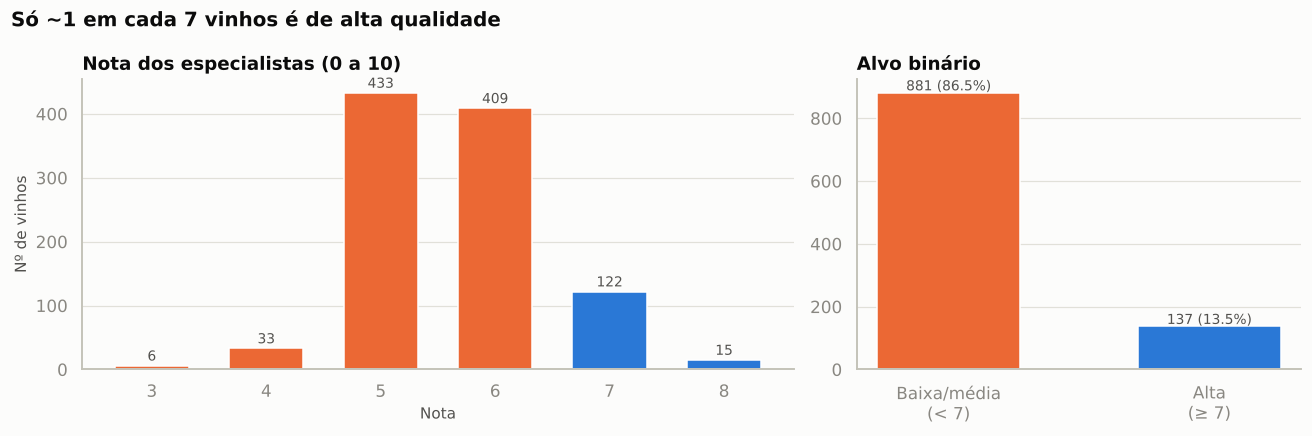

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.6, 1]})

cont = df["quality"].value_counts().sort_index()
cores = [viz.COLOR_HIGH if q >= 7 else viz.COLOR_LOW for q in cont.index]
axes[0].bar(cont.index.astype(str), cont.values, color=cores, width=0.65)
for x, v in zip(cont.index.astype(str), cont.values):
    axes[0].text(x, v + 8, f"{v}", ha="center", fontsize=9, color=viz.INK_2)
axes[0].set_title("Nota dos especialistas (0 a 10)", loc="left")
axes[0].set_xlabel("Nota")
axes[0].set_ylabel("Nº de vinhos")
axes[0].grid(axis="x", visible=False)

bin_ = df[TARGET].value_counts().sort_index()
axes[1].bar(["Baixa/média\n(< 7)", "Alta\n(≥ 7)"], bin_.values, color=[viz.COLOR_LOW, viz.COLOR_HIGH], width=0.55)
for i, v in enumerate(bin_.values):
    axes[1].text(i, v + 8, f"{v} ({v / len(df):.1%})", ha="center", fontsize=9, color=viz.INK_2)
axes[1].set_title("Alvo binário", loc="left")
axes[1].grid(axis="x", visible=False)

fig.suptitle("Só ~1 em cada 7 vinhos é de alta qualidade", fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
viz.save_fig(fig, "01_distribuicao_alvo")
plt.show()

**Leitura.**
- As notas se concentram em **5 e 6** (83% da base); notas extremas (3, 4 e 8) são raras — nenhum vinho tem nota
  abaixo de 3 ou acima de 8.
- Após a binarização, **137 vinhos (13,5%) são de alta qualidade** contra 881 (86,5%) de baixa/média:
  **as classes são desbalanceadas (≈ 1 : 6,4)**.

**Implicações para a modelagem**
- Um modelo que respondesse sempre "baixa/média" teria **86,5% de acurácia sem acertar nenhum vinho bom** →
  a acurácia não serve como métrica principal.
- Divisão treino/teste e validação cruzada **estratificadas** (mantêm a proporção em cada parte).
- Tratamento do desbalanceamento **só no treino**: pesos de classe (`class_weight="balanced"`) ou oversampling
  dentro do pipeline.

## 5. Estatística descritiva e distribuições

In [14]:
desc = df[FEATURES].describe().T
desc["assimetria"] = df[FEATURES].skew()
desc["cv_%"] = 100 * desc["std"] / desc["mean"]
desc.index = [label(c) for c in desc.index]
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,assimetria,cv_%
Acidez fixa,"1,018.000",8.289,1.741,4.600,7.100,7.900,9.100,15.900,1.037,21.009
Acidez volátil,"1,018.000",0.534,0.183,0.120,0.390,0.520,0.645,1.580,0.720,34.330
Ácido cítrico,"1,018.000",0.269,0.196,0.000,0.090,0.250,0.420,1.000,0.369,73.002
Açúcar residual,"1,018.000",2.524,1.315,0.900,1.900,2.200,2.600,15.500,4.350,52.085
Cloretos,"1,018.000",0.087,0.049,0.012,0.070,0.079,0.090,0.611,5.933,55.634
SO₂ livre,"1,018.000",15.649,10.177,1.000,7.000,13.000,21.000,68.000,1.172,65.031
SO₂ total,"1,018.000",46.326,33.124,6.000,21.000,38.000,62.000,289.000,1.680,71.502
Densidade,"1,018.000",0.997,0.002,0.990,0.996,0.997,0.998,1.004,0.092,0.192
pH,"1,018.000",3.312,0.158,2.740,3.210,3.310,3.400,4.010,0.258,4.764
Sulfatos,"1,018.000",0.657,0.168,0.330,0.550,0.620,0.720,2.000,2.425,25.508


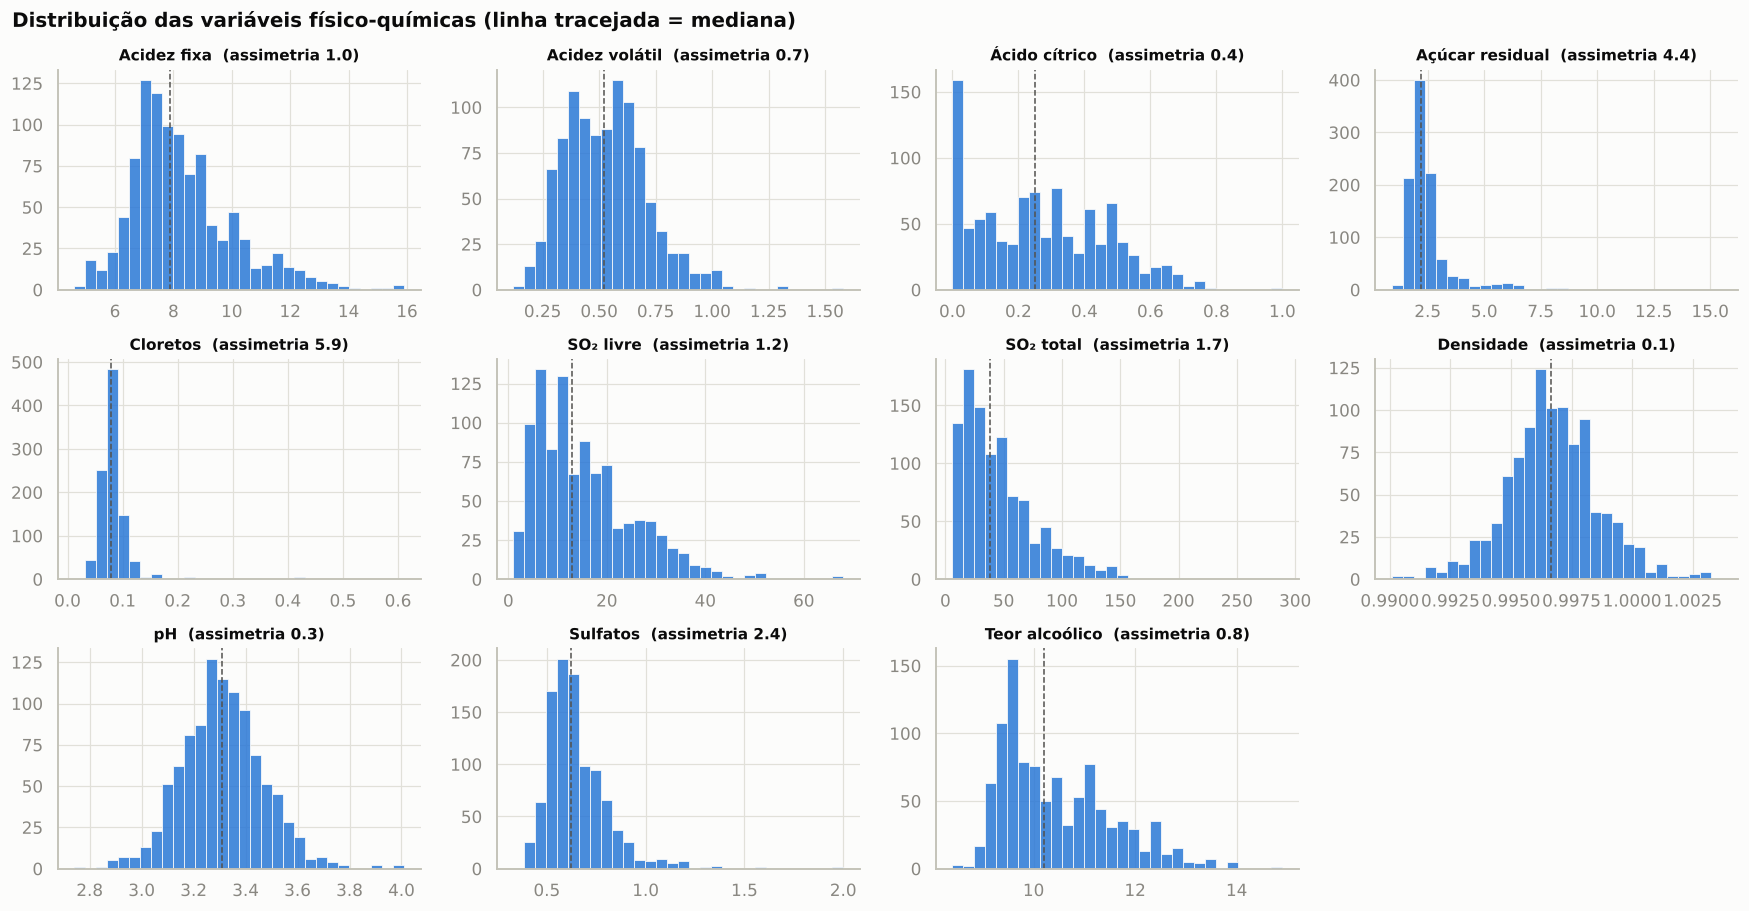

In [15]:
fig = viz.plot_hist_grid(df, FEATURES)
viz.save_fig(fig, "02_histogramas")
plt.show()

**Leitura das distribuições.**
- **Densidade** e **pH** são praticamente simétricos (assimetria ≈ 0,1 e 0,3) e de faixa estreita — o pH fica
  entre 2,7 e 4,0, típico de vinho tinto.
- **Cloretos (5,9)**, **açúcar residual (4,4)** e **sulfatos (2,4)** têm **forte assimetria à direita**: a maioria
  dos vinhos está numa faixa baixa e poucos têm valores muito altos (caudas longas). O SO₂ livre e o total também
  são assimétricos.
- **Teor alcoólico** vai de 8,4% a 14,9%, com mediana de 10,2% e cauda para a direita.
- As escalas são muito diferentes (densidade ≈ 1; SO₂ total até ~290) → modelos baseados em distância ou
  coeficientes (KNN, SVM, Regressão Logística) exigirão **padronização**.
- Variáveis assimétricas são candidatas a **transformação logarítmica** (reduz o peso das caudas sem descartar
  dados).

## 6. Outliers e valores inconsistentes

Critério de Tukey: valor abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR. Antes de remover qualquer coisa,
investigamos se os valores extremos são erro ou característica real do vinho.

In [16]:
outliers = iqr_outlier_table(df, FEATURES)
outliers["variavel"] = outliers["variavel"].map(label)
outliers.to_csv(RESULTS_DIR / "eda_outliers.csv", index=False)
outliers

,variavel,limite_inferior,limite_superior,outliers_abaixo,outliers_acima,total_outliers,pct_outliers
0,Açúcar residual,0.850,3.650,0,95,95,9.300
1,Cloretos,0.040,0.120,7,64,71,7.000
2,Sulfatos,0.295,0.975,0,41,41,4.000
3,Acidez fixa,4.100,12.100,0,37,37,3.600
4,SO₂ total,-40.500,123.500,0,33,33,3.200
5,Densidade,0.992,1.001,14,16,30,2.900
6,pH,2.925,3.685,10,14,24,2.400
7,SO₂ livre,-14.000,42.000,0,16,16,1.600
8,Acidez volátil,0.007,1.028,0,10,10,1.000
9,Teor alcoólico,6.950,13.750,0,6,6,0.600


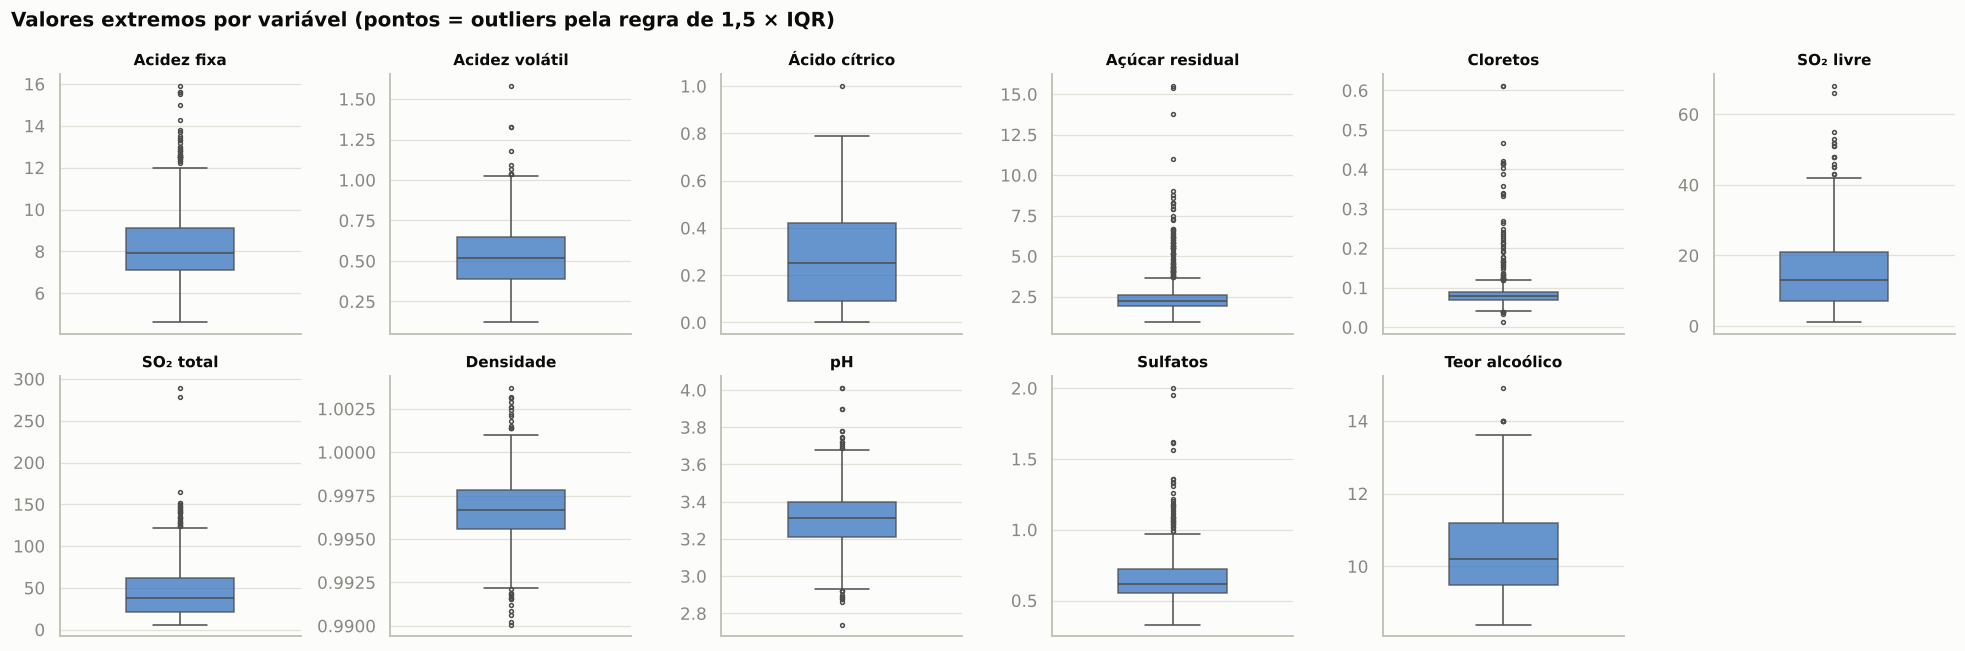

In [17]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for ax, c in zip(axes.flat, FEATURES):
    sns.boxplot(y=df[c], ax=ax, color=viz.COLOR_HIGH, width=0.45, linewidth=1, fliersize=2.5,
                boxprops={"alpha": 0.8})
    ax.set_title(label(c), fontsize=10)
    ax.set_ylabel("")
axes.flat[-1].set_visible(False)
fig.suptitle("Valores extremos por variável (pontos = outliers pela regra de 1,5 × IQR)",
             fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
viz.save_fig(fig, "03_outliers_boxplot")
plt.show()

In [18]:
# Os extremos são fisicamente plausíveis? Comparação com a faixa do conjunto e com a nota dos vinhos
extremos = pd.DataFrame({
    "variavel": [label(c) for c in ["chlorides", "residual_sugar", "sulphates", "total_sulfur_dioxide"]],
    "maximo": [df[c].max() for c in ["chlorides", "residual_sugar", "sulphates", "total_sulfur_dioxide"]],
    "p99": [df[c].quantile(0.99) for c in ["chlorides", "residual_sugar", "sulphates", "total_sulfur_dioxide"]],
    "% alta qualidade entre os outliers acima": [
        100 * df.loc[df[c] > df[c].quantile(0.75) + 1.5 * (df[c].quantile(0.75) - df[c].quantile(0.25)), TARGET].mean()
        for c in ["chlorides", "residual_sugar", "sulphates", "total_sulfur_dioxide"]
    ],
})
extremos.round({"% alta qualidade entre os outliers acima": 1})

,variavel,maximo,p99,% alta qualidade entre os outliers acima
0,Cloretos,0.611,0.355,6.200
1,Açúcar residual,15.500,8.066,22.100
2,Sulfatos,2.000,1.253,19.500
3,SO₂ total,289.000,143.830,6.100


In [19]:
# Valores inconsistentes: regras que qualquer amostra real de vinho tinto precisa cumprir
regras = {
    "algum valor negativo": (df[FEATURES] < 0).any(axis=1),
    "SO₂ livre maior que o SO₂ total": df["free_sulfur_dioxide"] > df["total_sulfur_dioxide"],
    "pH fora de 2,5 a 4,5": ~df["ph"].between(2.5, 4.5),
    "teor alcoólico fora de 7% a 16%": ~df["alcohol"].between(7, 16),
    "densidade fora de 0,98 a 1,01 g/cm³": ~df["density"].between(0.98, 1.01),
    "nota fora da escala 0 a 10": ~df["quality"].between(0, 10),
}
consistencia = pd.Series({regra: int(viola.sum()) for regra, viola in regras.items()},
                         name="amostras que violam a regra").to_frame()
consistencia

,amostras que violam a regra
algum valor negativo,0
SO₂ livre maior que o SO₂ total,0
"pH fora de 2,5 a 4,5",0
teor alcoólico fora de 7% a 16%,0
"densidade fora de 0,98 a 1,01 g/cm³",0
nota fora da escala 0 a 10,0


In [20]:
# Zeros: possíveis no ácido cítrico, mas vale conferir se se concentram em alguma classe
zeros = (df[FEATURES] == 0).sum()
print("Variáveis com valor zero:", {label(c): int(n) for c, n in zeros[zeros > 0].items()})
print(f"% alta qualidade entre os vinhos com ácido cítrico = 0: {df.loc[df['citric_acid'] == 0, TARGET].mean():.1%}")

Variáveis com valor zero: {'Ácido cítrico': 92}
% alta qualidade entre os vinhos com ácido cítrico = 0: 4.3%


**Leitura e decisão sobre outliers.**
- Os outliers se concentram nas variáveis assimétricas: **açúcar residual (9,3% das linhas)**, **cloretos (7,0%)**
  e **sulfatos (4,0%)**. São numerosos demais para serem erros de digitação isolados e formam caudas contínuas
  (não valores impossíveis).
- **Valores inconsistentes:** nenhuma amostra viola as regras físicas e químicas checadas acima (valores negativos,
  SO₂ livre maior que o total, pH, álcool, densidade ou nota fora da faixa possível). Os únicos zeros estão no
  **ácido cítrico** (92 vinhos, 9%): é um valor possível, porque muitos tintos não recebem ácido cítrico e o que a
  uva traz pode ser consumido por bactérias durante a fermentação. Esses vinhos são quase todos comuns (só 4,3% de
  alta qualidade), o que combina com o ácido cítrico ser um sinal positivo. Mantidos.
- Os extremos **carregam informação sobre a qualidade**: entre os vinhos com cloretos ou SO₂ total acima do limite
  superior, só ~6% são de alta qualidade (contra 13,5% na base); já entre os de açúcar residual e sulfatos altos,
  a proporção de alta qualidade é maior (~20%). Removê-los apagaria parte do sinal que o modelo precisa aprender —
  o mesmo alerta das aulas ("outlier nem sempre é ruim").
- Ponto de atenção: as duas amostras com SO₂ total muito acima das demais (278 e 289 mg/dm³, quase o dobro da
  3ª maior, 165) têm nota 7. Podem ser lotes muito corrigidos com conservante ou erro de registro — como são só
  2 linhas, mantemos e deixamos a transformação log e os modelos de árvore reduzirem seu peso.

**Decisão:** **manter os outliers** e reduzir sua influência com **transformação log1p** nas variáveis
assimétricas (para modelos sensíveis a escala) e usar também **modelos de árvore**, que são robustos a extremos.

## 7. Comparação entre vinhos de alta e baixa/média qualidade

Perfil de cada classe (mediana, mais robusta que a média com caudas longas) e distribuições lado a lado.

In [21]:
perfil = df.groupby(TARGET)[FEATURES].median().T
perfil.columns = ["Baixa/média (mediana)", "Alta (mediana)"]
perfil["diferença_%"] = 100 * (perfil["Alta (mediana)"] / perfil["Baixa/média (mediana)"] - 1)
perfil.index = [label(c) for c in perfil.index]
perfil.sort_values("diferença_%").round(3)

,Baixa/média (mediana),Alta (mediana),diferença_%
Acidez volátil,0.550,0.360,-34.545
SO₂ total,41.000,27.000,-34.146
SO₂ livre,14.000,12.000,-14.286
Cloretos,0.080,0.071,-11.250
pH,3.310,3.270,-1.208
Densidade,0.997,0.995,-0.126
Açúcar residual,2.200,2.300,4.545
Acidez fixa,7.800,8.600,10.256
Teor alcoólico,10.000,11.700,17.000
Sulfatos,0.600,0.740,23.333


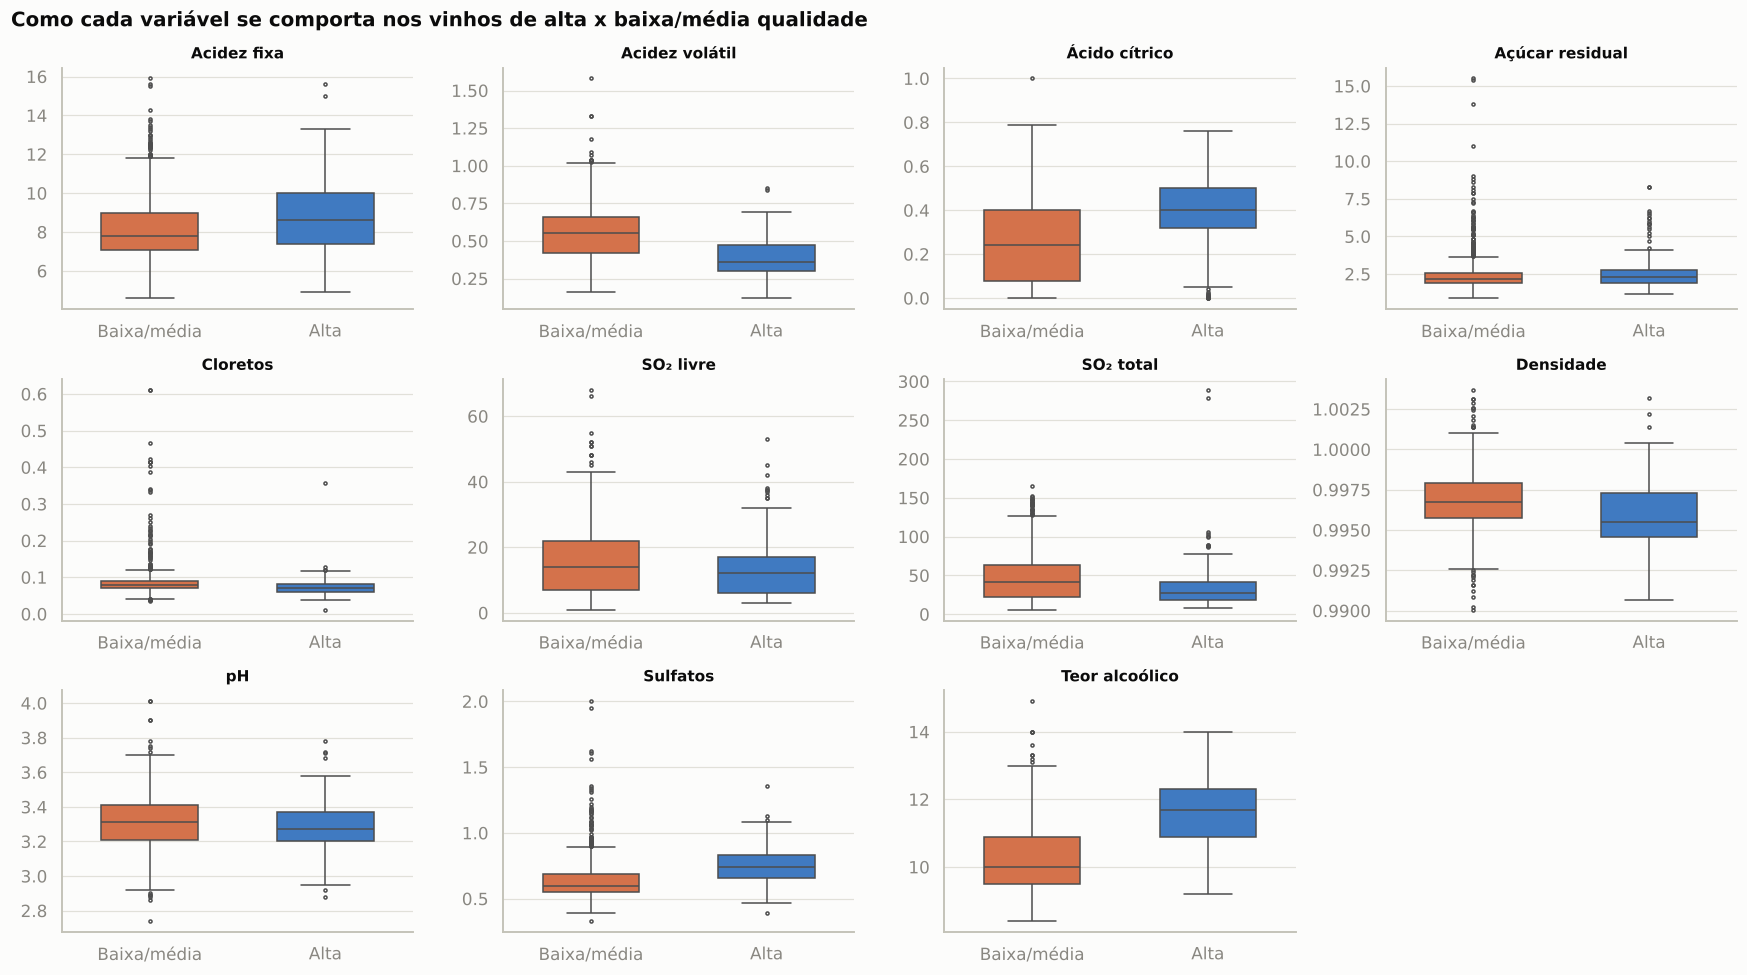

In [22]:
fig = viz.plot_box_by_class(df, FEATURES)
viz.save_fig(fig, "04_boxplot_por_classe")
plt.show()

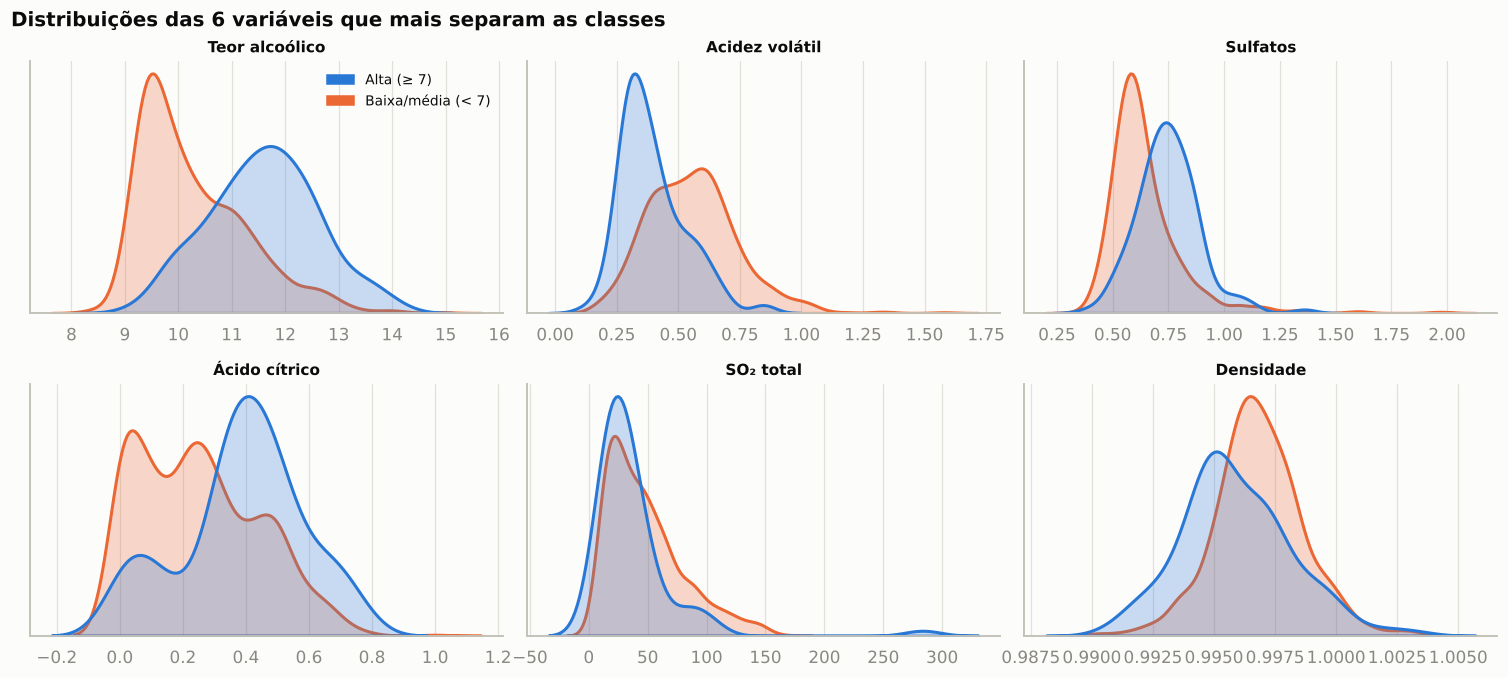

In [23]:
top = ["alcohol", "volatile_acidity", "sulphates", "citric_acid", "total_sulfur_dioxide", "density"]
fig = viz.plot_kde_by_class(df, top)
fig.suptitle("Distribuições das 6 variáveis que mais separam as classes", fontsize=13,
             fontweight="bold", x=0.01, ha="left", y=1.02)
viz.save_fig(fig, "05_densidade_por_classe")
plt.show()

**Leitura.** O vinho de alta qualidade típico, comparado ao de baixa/média:
- tem **mais álcool** (mediana 11,7% vs 10,0%);
- tem **muito menos acidez volátil** (0,36 vs 0,55 g/dm³ — cerca de 35% menos ácido acético);
- tem **mais sulfatos** (0,74 vs 0,60) e **mais ácido cítrico** (0,40 vs 0,24);
- tem **menos SO₂ total** (27 vs 41 mg/dm³) e **densidade menor** (consequência do álcool mais alto).

Açúcar residual, pH e SO₂ livre quase não mudam entre as classes. As curvas de densidade mostram que **nenhuma
variável separa as classes sozinha** (há sobreposição), mas álcool e acidez volátil deslocam bastante as
distribuições — o modelo precisará combinar várias variáveis.

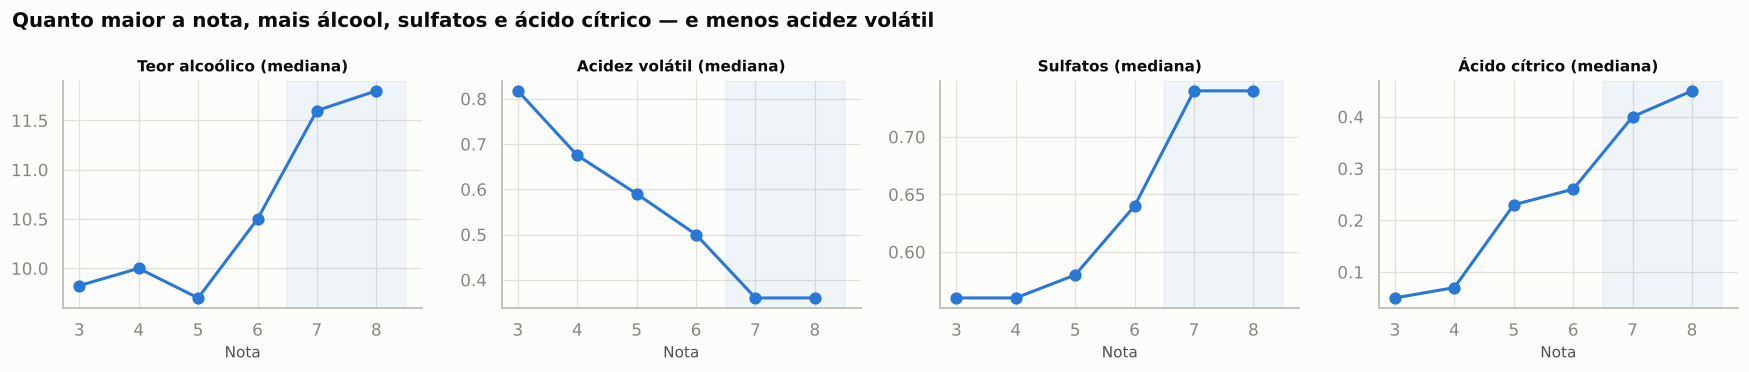

,alcohol,volatile_acidity,sulphates,citric_acid
quality,,,,
3,9.825,0.818,0.560,0.050
4,10.000,0.675,0.560,0.070
5,9.700,0.590,0.580,0.230
6,10.500,0.500,0.640,0.260
7,11.600,0.360,0.740,0.400
8,11.800,0.360,0.740,0.450


In [24]:
# Tendência ao longo da nota original: confirma que o padrão é gradual e não um efeito do corte em 7
tendencia = df.groupby("quality")[["alcohol", "volatile_acidity", "sulphates", "citric_acid"]].median()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, c in zip(axes, tendencia.columns):
    ax.plot(tendencia.index, tendencia[c], color=viz.COLOR_HIGH, linewidth=2, marker="o", markersize=7)
    ax.axvspan(6.5, 8.5, color=viz.COLOR_HIGH, alpha=0.06)
    ax.set_title(f"{label(c)} (mediana)", fontsize=10)
    ax.set_xlabel("Nota")
    ax.set_xticks(tendencia.index)
fig.suptitle("Quanto maior a nota, mais álcool, sulfatos e ácido cítrico — e menos acidez volátil",
             fontsize=13, fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
viz.save_fig(fig, "06_tendencia_por_nota")
plt.show()
tendencia.round(3)

## 8. Correlações

Usamos a correlação de **Pearson** (relação linear, como nas aulas) e conferimos com a de **Spearman** (baseada em
postos, mais robusta a outliers e a relações não lineares). Lembrete: **correlação não é causalidade** — cada
relação abaixo é justificada pela química do vinho.

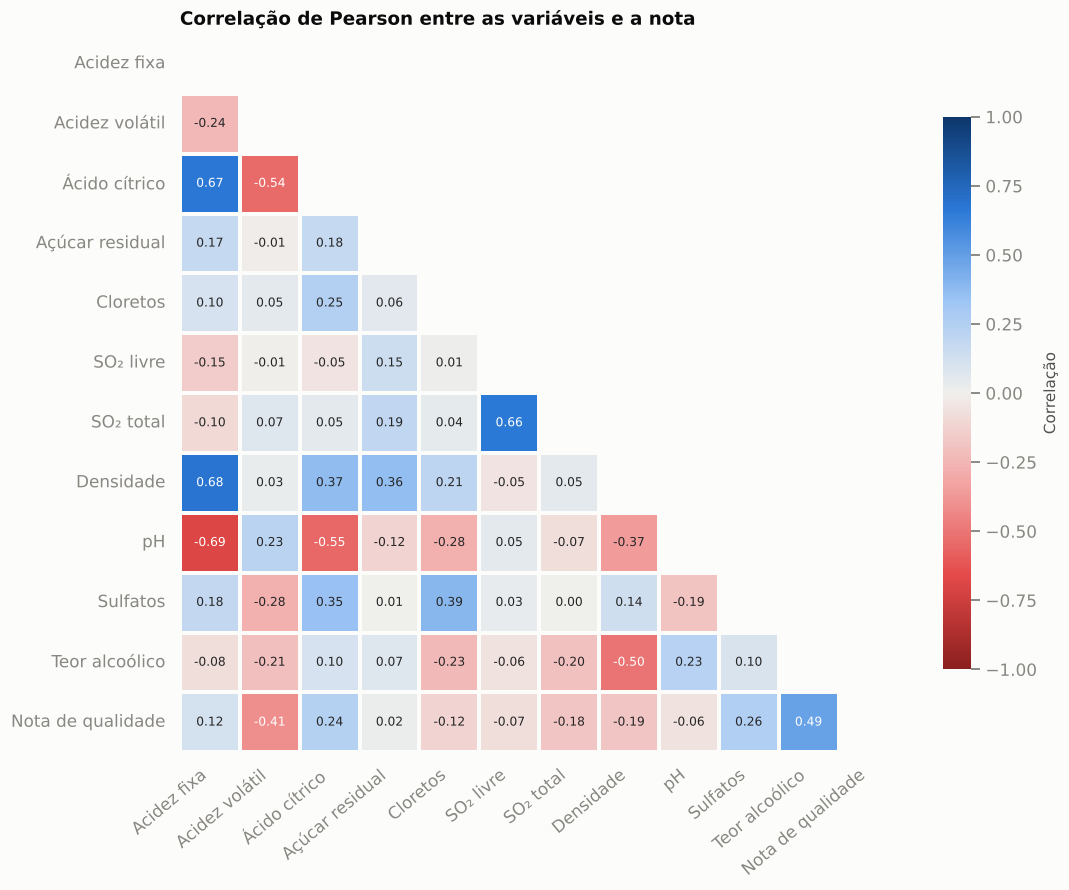

In [25]:
corr = df[FEATURES + ["quality"]].corr(method="pearson")
fig = viz.plot_corr_heatmap(corr, "Correlação de Pearson entre as variáveis e a nota")
viz.save_fig(fig, "07_correlacao_heatmap")
plt.show()

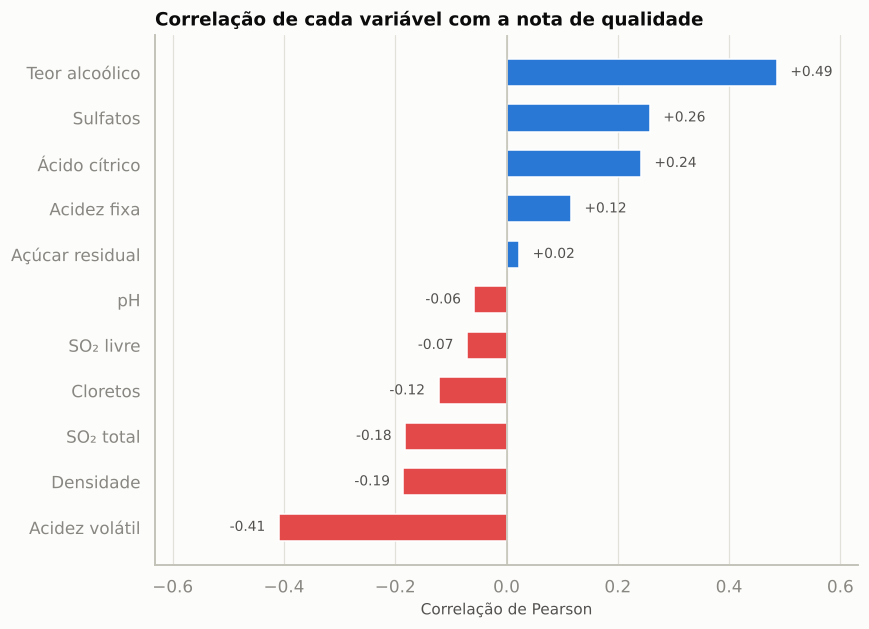

,pearson_nota,spearman_nota,pearson_alvo_binario
Acidez volátil,-0.410,-0.400,-0.300
Densidade,-0.190,-0.180,-0.170
SO₂ total,-0.180,-0.200,-0.110
Cloretos,-0.120,-0.210,-0.110
SO₂ livre,-0.070,-0.070,-0.070
pH,-0.060,-0.040,-0.070
Açúcar residual,0.020,0.030,0.060
Acidez fixa,0.120,0.110,0.110
Ácido cítrico,0.240,0.230,0.240
Sulfatos,0.260,0.390,0.210


In [26]:
corr_alvo = pd.DataFrame({
    "pearson_nota": corr["quality"].drop("quality"),
    "spearman_nota": df[FEATURES + ["quality"]].corr(method="spearman")["quality"].drop("quality"),
    "pearson_alvo_binario": df[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET),
}).sort_values("pearson_nota")
fig = viz.plot_bar_signed(corr_alvo["pearson_nota"], "Correlação de cada variável com a nota de qualidade",
                          "Correlação de Pearson")
viz.save_fig(fig, "08_correlacao_com_qualidade")
plt.show()
corr_alvo.rename(index=label).round(2)

In [27]:
# Pares de variáveis explicativas com correlação forte/moderada (|r| >= 0,4)
pares = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) >= 0.4:
            pares.append({"variável A": label(a), "variável B": label(b), "pearson": round(r, 2)})
pd.DataFrame(pares).sort_values("pearson", key=abs, ascending=False)

,variável A,variável B,pearson
2,Acidez fixa,pH,-0.690
1,Acidez fixa,Densidade,0.680
0,Acidez fixa,Ácido cítrico,0.670
5,SO₂ livre,SO₂ total,0.660
4,Ácido cítrico,pH,-0.550
3,Acidez volátil,Ácido cítrico,-0.540
6,Densidade,Teor alcoólico,-0.500


### Justificativa de cada correlação

**a) Relações entre as variáveis explicativas (|r| ≥ 0,4)**

| Par | r | Por que faz sentido |
|---|---|---|
| Acidez fixa × pH | −0,69 | pH mede a concentração de íons H⁺ em escala log: mais ácidos fixos → pH menor. Relação química direta. |
| Acidez fixa × densidade | +0,68 | Ácidos dissolvidos aumentam a massa da solução, elevando a densidade. |
| Acidez fixa × ácido cítrico | +0,67 | O ácido cítrico é um dos ácidos fixos — ele é parte do que a acidez fixa mede. |
| SO₂ livre × SO₂ total | +0,66 | O SO₂ livre é uma parcela do total (total = livre + combinado). |
| Ácido cítrico × pH | −0,55 | Mesmo mecanismo da acidez fixa: mais ácido → pH menor. |
| Acidez volátil × ácido cítrico | −0,54 | Bactérias láticas consomem ácido cítrico e produzem ácido acético; vinhos que preservaram o cítrico tendem a ter menos acético. |
| Densidade × teor alcoólico | −0,50 | O etanol (0,79 g/cm³) é menos denso que a água; e mais álcool significa que mais açúcar (denso) foi fermentado. |

Essas redundâncias (multicolinearidade) não impedem a modelagem, mas pedem **regularização** na Regressão
Logística e cuidado ao interpretar coeficientes isoladamente (ex.: o efeito da densidade se confunde com o do
álcool).

**b) Relação de cada variável com a qualidade**

| Variável | r (nota) | Justificativa |
|---|---|---|
| Teor alcoólico | **+0,49** | Maior correlação. Uvas mais maduras e fermentação completa geram mais álcool, corpo e intensidade aromática — atributos valorizados na prova. |
| Acidez volátil | **−0,41** | É o ácido acético: em excesso dá aroma de vinagre, um defeito clássico. Penalizado pelos avaliadores. |
| Sulfatos | +0,26 (Spearman +0,39) | O sulfato de potássio contribui com SO₂, que protege contra oxidação e micróbios, preservando frescor. A correlação é maior em Spearman: o efeito satura e valores muito altos (outliers) não ajudam mais. |
| Ácido cítrico | +0,24 | Traz frescor e equilíbrio; também indica menor degradação por bactérias (relação inversa com a acidez volátil). |
| Densidade | −0,19 | Reflexo indireto do álcool (relação acima), não uma causa própria. |
| SO₂ total | −0,18 | Muito SO₂ mascara aromas e costuma indicar vinhos que precisaram de mais correção. |
| Cloretos | −0,12 (Spearman −0,21) | Sal em excesso dá gosto salgado; o efeito aparece melhor em Spearman por causa da cauda longa. |
| Acidez fixa | +0,12 | Leve: acidez dá estrutura, mas o efeito se mistura ao do ácido cítrico. |
| SO₂ livre, pH, açúcar residual | ≈ 0 | Vinhos tintos secos, com pouca variação dessas medidas no conjunto; isoladamente não diferenciam qualidade. |

**Resumo:** nenhuma correlação com a qualidade é forte (máx. |r| ≈ 0,5) — a qualidade depende da **combinação**
de várias características, o que justifica usar modelos multivariados.

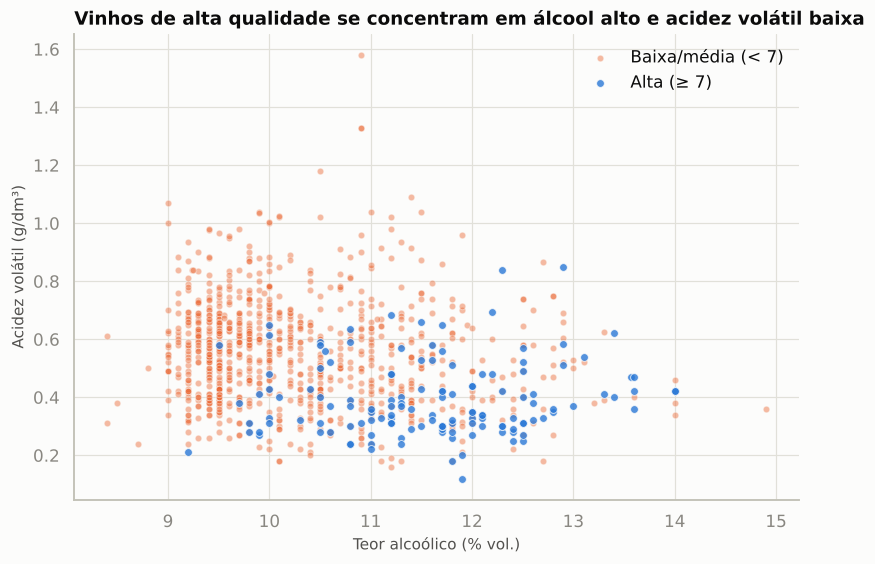

In [28]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for k in (0, 1):
    sub = df[df[TARGET] == k]
    ax.scatter(sub["alcohol"], sub["volatile_acidity"], s=26 if k else 18, alpha=0.8 if k else 0.45,
               color=viz.CLASS_PALETTE[k], edgecolor=viz.SURFACE, linewidth=0.6, label=viz.CLASS_NAMES[k])
ax.set_xlabel("Teor alcoólico (% vol.)")
ax.set_ylabel("Acidez volátil (g/dm³)")
ax.set_title("Vinhos de alta qualidade se concentram em álcool alto e acidez volátil baixa", loc="left")
ax.legend(loc="upper right")
viz.save_fig(fig, "09_alcool_vs_acidez_volatil")
plt.show()

O gráfico de dispersão confirma visualmente as duas correlações mais fortes: os vinhos de alta qualidade (azul)
ocupam o **canto inferior direito** (álcool acima de ~11% e acidez volátil abaixo de ~0,5). Ainda assim há
sobreposição — a separação perfeita não existe só com duas variáveis.

## 9. Testes de hipótese

Para sair do "achismo" visual, testamos estatisticamente se cada variável difere entre as classes — o que também
verifica as hipóteses H1 a H4 registradas na seção 1.5.

1. **Shapiro-Wilk** (normalidade), por classe. H₀: a distribuição é normal. **p < 0,05 → rejeita a normalidade.**
2. Como a normalidade é rejeitada na maioria dos casos, usamos o teste **não paramétrico de Mann-Whitney U**.
   H₀: as distribuições das duas classes são iguais; H₁: são diferentes. **p < 0,05 → diferença significativa.**
3. Para medir o **tamanho** da diferença (não só se existe), calculamos a correlação rank-bisserial
   (−1 a +1; |r| ≥ 0,3 moderado, ≥ 0,5 grande). Como testamos 11 variáveis, aplicamos a correção de Bonferroni
   (α = 0,05 / 11 ≈ 0,0045).

In [29]:
alfa = 0.05
alfa_bonf = alfa / len(FEATURES)
linhas = []
for c in FEATURES:
    alta = df.loc[df[TARGET] == 1, c]
    baixa = df.loc[df[TARGET] == 0, c]
    p_sh_alta = shapiro(alta).pvalue
    p_sh_baixa = shapiro(baixa).pvalue
    u, p_mw = mannwhitneyu(alta, baixa, alternative="two-sided")
    efeito = 2 * u / (len(alta) * len(baixa)) - 1          # rank-bisserial: >0 = maior na classe alta
    linhas.append({
        "variável": label(c),
        "Shapiro p (alta)": p_sh_alta,
        "Shapiro p (baixa/média)": p_sh_baixa,
        "normal nas duas?": "sim" if min(p_sh_alta, p_sh_baixa) >= alfa else "não",
        "Mann-Whitney p": p_mw,
        f"significativo (p < {alfa_bonf:.4f})": "sim" if p_mw < alfa_bonf else "não",
        "efeito (rank-bisserial)": efeito,
        "mediana alta": alta.median(),
        "mediana baixa/média": baixa.median(),
    })
testes = pd.DataFrame(linhas).sort_values("efeito (rank-bisserial)", key=abs, ascending=False)
testes.to_csv(RESULTS_DIR / "eda_testes_estatisticos.csv", index=False)
with pd.option_context("display.float_format", lambda x: f"{x:.2e}" if abs(x) < 1e-3 and x != 0 else f"{x:.3f}"):
    display(testes)

,variável,Shapiro p (alta),Shapiro p (baixa/média),normal nas duas?,Mann-Whitney p,significativo (p < 0.0045),efeito (rank-bisserial),mediana alta,mediana baixa/média
10,Teor alcoólico,0.454,6.22e-22,não,6.92e-35,sim,0.653,11.700,10.000
1,Acidez volátil,2.43e-06,1.53e-11,não,2.03e-25,sim,-0.553,0.360,0.550
9,Sulfatos,0.001,1.73e-32,não,1.01e-20,sim,0.495,0.740,0.600
2,Ácido cítrico,2.86e-04,3.95e-17,não,8.76e-14,sim,0.395,0.400,0.240
4,Cloretos,5.11e-18,2.79e-45,não,6.82e-10,sim,-0.327,0.071,0.080
7,Densidade,0.079,1.78e-06,não,3.90e-08,sim,-0.292,0.995,0.997
6,SO₂ total,2.39e-18,3.56e-23,não,7.91e-07,sim,-0.262,27.000,41.000
0,Acidez fixa,0.011,8.24e-20,não,3.49e-04,sim,0.190,8.600,7.800
5,SO₂ livre,1.27e-10,4.82e-22,não,0.016,não,-0.128,12.000,14.000
8,pH,0.038,3.24e-05,não,0.022,não,-0.121,3.270,3.310


**Leitura dos testes.**
- **Shapiro-Wilk:** a normalidade é rejeitada em todas as variáveis da classe baixa/média e em quase todas da classe alta (exceções: teor alcoólico e densidade na classe alta),
  confirmando o que os histogramas mostraram → o teste t não é adequado; o Mann-Whitney é.
- **Mann-Whitney:** **8 das 11 variáveis diferem significativamente** entre as classes mesmo com a correção de
  Bonferroni. SO₂ livre e pH ficam no limite (significativos só a 5%, não após a correção) e **açúcar residual não
  difere** (p ≈ 0,13).
- **Tamanho do efeito:** grande para **teor alcoólico (+0,65)** e **acidez volátil (−0,55)**; no limite entre
  moderado e grande para **sulfatos (+0,495)**; moderado para **ácido cítrico (+0,40)** e **cloretos (−0,33)**. Esses cinco são os candidatos mais fortes a
  explicar a qualidade.

### Resultado das hipóteses iniciais (seção 1.5)

| # | Hipótese | Evidência | Conclusão |
|---|---|---|---|
| H1 | Mais teor alcoólico nos vinhos de alta qualidade | Mediana 11,7% x 10,0%; Mann-Whitney p < 0,001; efeito +0,65 (grande) | **Confirmada** |
| H2 | Menos acidez volátil nos vinhos de alta qualidade | Mediana 0,36 x 0,55 g/dm³; p < 0,001; efeito −0,55 (grande) | **Confirmada** |
| H3 | Mais sulfatos nos vinhos de alta qualidade | Mediana 0,74 x 0,60 g/dm³; p < 0,001; efeito +0,50 (no limite de grande) | **Confirmada** |
| H4 | Açúcar residual não diferencia as classes | Mediana 2,3 x 2,2 g/dm³; p ≈ 0,13; efeito +0,08 | **Consistente com a hipótese** (não há diferença significativa) |

## 10. Conclusões da EDA e decisões para o pré-processamento

**O que os dados mostram**
1. **Desbalanceamento:** apenas 13,5% dos vinhos são de alta qualidade (1 em cada 7).
2. **Os três sinais mais fortes de qualidade** são **mais teor alcoólico**, **menos acidez volátil** e **mais
   sulfatos**; ácido cítrico (+) e cloretos/SO₂ total (−) vêm em seguida. O padrão é gradual ao longo da nota.
3. **Nenhuma variável separa as classes sozinha** (correlação máxima ≈ 0,5) → precisamos de modelos que combinem
   variáveis.
4. Há **redundância química** entre acidez fixa, ácido cítrico, pH e densidade, e entre SO₂ livre e total.
5. Base limpa: **sem nulos** e **sem valores inconsistentes**; `id` sem valor analítico; **10,9% de linhas repetidas**.
6. **Hipóteses iniciais:** H1 (mais álcool), H2 (menos acidez volátil) e H3 (mais sulfatos) foram confirmadas com
   efeito grande (sulfatos no limite); H4 (açúcar residual não diferencia) é consistente com os dados.

**Decisões levadas ao notebook 02**

| Tema | Decisão | Justificativa |
|---|---|---|
| Alvo | `alta_qualidade` = 1 se nota ≥ 7 (seção 1) | Corte sugerido no enunciado; separa o topo de ~14% |
| Nota original (`quality`) | Excluir das variáveis explicativas | É a origem do alvo — usá-la seria vazamento |
| `id` | Remover | Identificador, sem informação química |
| Duplicatas | Remover (manter 1ª ocorrência) | Evita peso duplo e vazamento treino/teste |
| Nulos | Nada a fazer | Não há |
| Outliers | Manter; log1p nas variáveis assimétricas | São reais e informativos |
| Escala | StandardScaler dentro do pipeline (ajustado só no treino) | Escalas muito diferentes; exigido por KNN/SVM/Regressão Logística |
| Desbalanceamento | Divisão estratificada + `class_weight="balanced"` / oversampling só no treino | Evita modelo que ignora a classe minoritária |
| Métrica | F1 da classe "alta" (+ recall, precisão, ROC-AUC, PR-AUC) | Acurácia engana com 86,5% na classe majoritária |
| Novas variáveis | Acidez total, proporção SO₂ livre/total, SO₂ combinado, álcool × sulfatos | Resumem relações químicas vistas na EDA; testadas como hiperparâmetro |

In [30]:
# Lista das figuras geradas por este notebook
sorted(p.name for p in (RESULTS_DIR / "figures").glob("0*.png"))

['01_distribuicao_alvo.png',
 '02_histogramas.png',
 '03_outliers_boxplot.png',
 '04_boxplot_por_classe.png',
 '05_densidade_por_classe.png',
 '06_tendencia_por_nota.png',
 '07_correlacao_heatmap.png',
 '08_correlacao_com_qualidade.png',
 '09_alcool_vs_acidez_volatil.png']